# CloneCheck: is that really your grandson on the phone?

**Veritas AI International High School Hackathon 2026 · AI + Finance · Gosha**

*This project is a prototype and is not financial advice.*

CloneCheck helps a grandparent who gets a call from "a grandchild in trouble" by taking a few seconds of the caller's voice and saying whether it sounds like a real person or an AI-generated voice.

**In short:** it catches every AI voice from the generators it trained on, 70% from generators it never met, and only 30% of AI copies of my own voice. This notebook shows the data, trains each version of the detector, and reports every result, including the ones that went badly.

It runs in about a minute, because the slow part (turning 14,375 audio clips into numbers) was done in advance and saved in the repository.

## 0. Setup

In [1]:
import os, subprocess
in_project = os.path.exists("clonecheck/config.py")
in_project or subprocess.run("git clone -q --depth 1 https://github.com/ImGosha/clonecheck.git", shell=True)
in_project or os.chdir("clonecheck")

True

In [2]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
from IPython.display import Audio, Image, display
from clonecheck import detect, report
from clonecheck.config import TRAIN_SOURCES
pd.set_option("display.max_colwidth", 100)

## 1. The data

Real voices come from ten public datasets and my own recordings. Fake voices come from eight AI voice generators, which read out the same texts as the real clips.

The key design choice is the **role** column. A generator or dataset marked `train` is one the detector learns from. `dev` ones are never trained on and were used to choose settings. `test` ones were never trained on and never used to choose anything: they were scored once, at the end.

In [3]:
report.clip_counts()

split                                                      train  dev  test
label role  who                                                            
real  train FLEURS                                           750  709   713
            Golos                                            300  300   300
            LibriSpeech                                      300  300   300
            RuLibriSpeech                                    300  150   200
            VoxPopuli                                        300  150   200
      test  AMI (meetings)                                     0    0   100
            MInDS-14 (calls to a bank)                         0    0   400
            My own voice                                       0    0    30
            My own voice, second recording                     0    0    30
            Podlodka (podcast)                                 0    0    50
      dev   English Dialects                                   0  200     0
            SOVA                                               0  200     0
fake  train MMS                                              716  606   680
            Piper                                            952  606   680
            macOS say                                        841  606   680
      test  Bark                                               0    0   200
            Chatterbox                                         0    0   180
            Chatterbox copying my voice                        0    0    30
            Chatterbox copying my voice, second recording      0    0    30
            Kokoro                                             0    0   365
            Vosk                                               0    0   315
      dev   Silero                                             0  606     0

### Listen

One sentence from the test set, said by a real person and by four AI voice generators. The last two columns are CloneCheck's AI-voice score for each clip (0 = sure it is real, 1 = sure it is AI; the alarm goes off above 0.08).

In [4]:
examples = pd.read_csv("examples/examples.csv")
print(examples["text"][0])
examples.drop(columns=["text", "clip_id"])

He did not set a figure for the cuts, saying they will be made based on China's economic output.


,file,what,score_clean,score_phone
0,real.wav,a real person (FLEURS),0.000,0.000
1,piper.wav,AI voice: piper,1.000,1.000
2,kokoro.wav,AI voice: kokoro,0.337,0.009
3,chatterbox.wav,AI voice: chatterbox,0.395,0.419
4,bark.wav,AI voice: bark,0.964,0.854


In [5]:
for row in examples.itertuples():
    print(row.what)
    display(Audio(f"examples/{row.file}"))

a real person (FLEURS)


AI voice: piper


AI voice: kokoro


AI voice: chatterbox


AI voice: bark


The same real clip through the simulated phone line, which is how every clip is also tested:

In [6]:
Audio("examples/real_phone.wav")

## 2. Turning sound into numbers, and the model

Each clip is passed through **XLS-R**, a speech model Meta pretrained on 436,000 hours of speech in 128 languages. We do not train XLS-R. We keep the average of its layer-10 activations: 1,024 numbers per clip. The baseline uses 80 classic audio numbers (MFCCs) instead.

Those numbers were computed in advance (`scripts/features.py`). Here they are loaded:

In [7]:
features = detect.load_features(layers=[10])
clips = detect.load_clips()
train_clips = clips[clips["split"] == "train"]
dev_clips = clips[clips["split"] == "dev"]
fresh = clips[clips["text_source"] == "own2"]            # my second recording, added later (section 7)
test_clips = clips[(clips["split"] == "test") & (clips["text_source"] != "own2")]
print(len(train_clips), "train clips,", len(dev_clips), "dev clips,", len(test_clips), "test clips")
print("numbers per clip:", detect.matrix(features, train_clips[:1], "clean", "xlsr", 10).shape[1])

4459 train clips, 4433 dev clips, 5423 test clips
numbers per clip: 1024


The detector itself is a **logistic regression**: it learns one weight for each of the 1,024 numbers and outputs the probability that the voice is AI-generated. `detect.train` is a thin wrapper around scikit-learn's `StandardScaler` and `LogisticRegression`.

## 3. Version 1: real voices from one dataset

The first version learned from real voices in a single dataset (FLEURS) and fakes from three generators.

In [8]:
fleurs_only = train_clips[train_clips["text_source"] == "fleurs"]
version1 = detect.train(features, fleurs_only, "xlsr", 10, conditions=("clean",))
real_dev_fleurs = dev_clips[(dev_clips["label"] == "real") & (dev_clips["source"] == "fleurs")]
detect.set_threshold(version1, features, real_dev_fleurs)   # alarm level: at most 5% of real dev clips flagged
report.flag_table(version1, features, dev_clips)

lang                                       en    ru    en    ru
condition                               clean clean phone phone
label met              who                                     
real  trained on       FLEURS              2%    1%    8%    9%
                       LibriSpeech        85%         88%      
                       Golos                    22%         36%
                       VoxPopuli          95%         96%      
                       RuLibriSpeech            98%         99%
      never trained on English Dialects   92%         92%      
                       SOVA                     52%         71%
fake  trained on       macOS say         100%  100%  100%  100%
                       Piper             100%  100%  100%  100%
                       MMS               100%  100%  100%  100%
      never trained on Silero            100%  100%  100%  100%

Read the `fake` rows first: **every fake is caught**, including Silero, a generator it never trained on. That looked too good to be true.

Now the `real` rows. FLEURS voices are fine. But it flags most real people from every other dataset: audiobook readers (LibriSpeech, RuLibriSpeech), politicians (VoxPopuli), people with regional accents (English Dialects).

Version 1 did not learn what a human voice sounds like. It learned what a *FLEURS recording* sounds like, and calls everything else fake. That is also why it "catches" every fake.

## 4. Version 2 (CloneCheck): real voices from five datasets

The fix: real voices from five datasets in training, each training clip also heard through the simulated phone line, and the alarm level set on dev voices from all five.

In [9]:
clonecheck = detect.train(features, train_clips, "xlsr", 10, conditions=("clean", "phone"))
real_dev = dev_clips[(dev_clips["label"] == "real") & dev_clips["source"].isin(TRAIN_SOURCES)]
detect.set_threshold(clonecheck, features, real_dev)
report.flag_table(clonecheck, features, dev_clips)

lang                                       en    ru    en    ru
condition                               clean clean phone phone
label met              who                                     
real  trained on       FLEURS              0%    0%    0%    1%
                       LibriSpeech         9%         13%      
                       Golos                     4%          6%
                       VoxPopuli           0%          0%      
                       RuLibriSpeech            23%         20%
      never trained on English Dialects   17%         22%      
                       SOVA                      6%         10%
fake  trained on       macOS say         100%  100%  100%  100%
                       Piper             100%  100%  100%  100%
                       MMS               100%  100%  100%  100%
      never trained on Silero             99%   90%   98%   90%

On the two real datasets it never trained on (English Dialects, SOVA), false alarms fell from 52-92% to 6-22%, and it still catches 91-99% of Silero. These dev results are what the settings were chosen on. The settings were then frozen and committed before the test below.

## 5. The test (scored once)

Baselines for comparison: always saying "real", and the same logistic regression on the 80 simple audio numbers.

In [10]:
simple = detect.train(features, train_clips, "mfcc", None, conditions=("clean", "phone"))
detect.set_threshold(simple, features, real_dev)
methods = {"Always say \"real\"": None, "Simple audio features": simple,
           "Version 1 (one real dataset)": version1, "CloneCheck (many real datasets)": clonecheck}
report.compare(methods, features, test_clips, condition="phone")

,AI voices caught: new generators,Real people flagged: new datasets,AI voices caught: known generators,Real people flagged: known datasets
Method,,,,
"Always say ""real""",0% (0 of 1090),0% (0 of 580),0% (0 of 2040),0% (0 of 1713)
Simple audio features,53% (583 of 1090),19% (113 of 580),69% (1406 of 2040),7% (118 of 1713)
Version 1 (one real dataset),97% (1055 of 1090),53% (307 of 580),100% (2040 of 2040),47% (807 of 1713)
CloneCheck (many real datasets),70% (760 of 1090),8% (45 of 580),100% (2038 of 2040),4% (69 of 1713)


These are the numbers for clips heard through the phone line. "New" means generators and datasets the detector never met.

- **Version 1** catches 97% of new-generator fakes only because it flags 53% of new real people too.
- **CloneCheck** catches 70% and wrongly flags 8%. That is far better than the simple baseline on both counts, and still not good enough for someone to rely on.
- On generators it trained on, CloneCheck catches 100%. The drop to 70% is the cost of a generator being new.

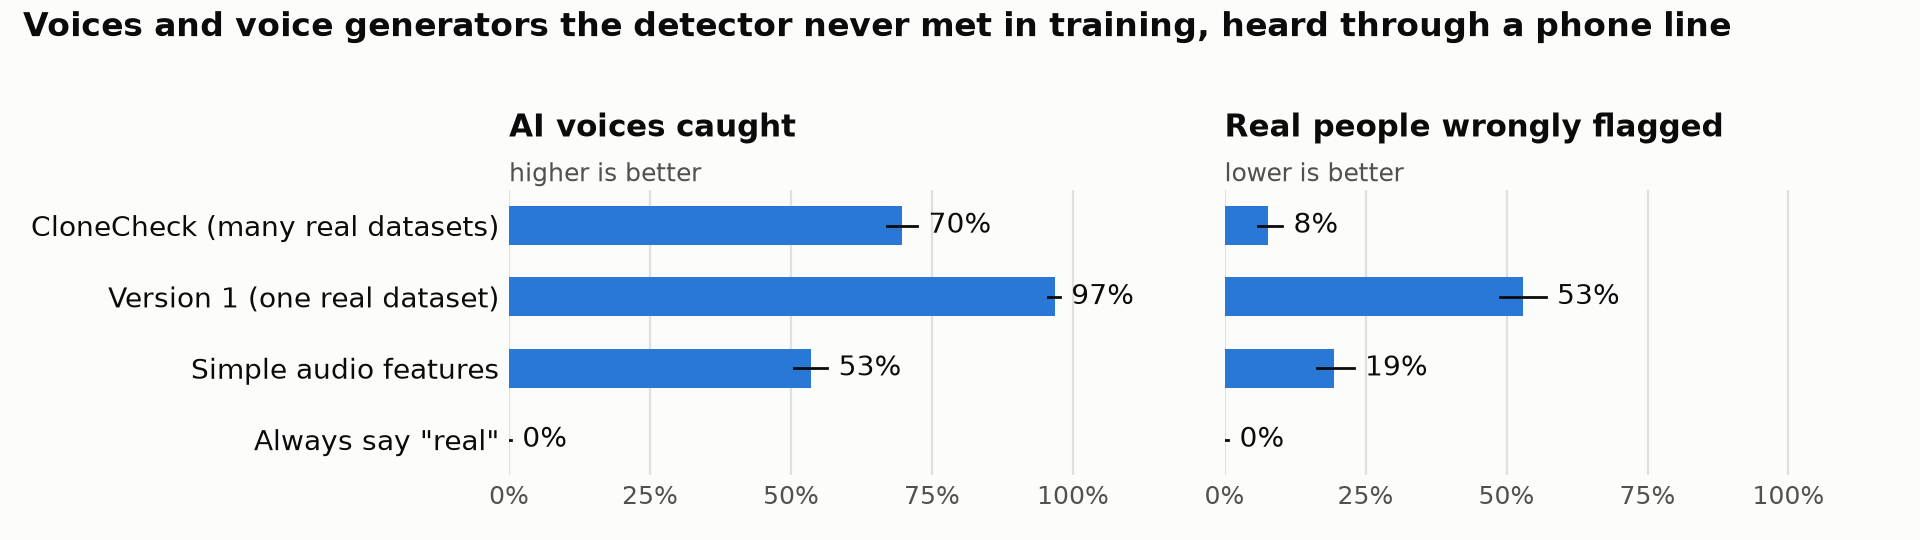

In [11]:
display(Image("results/test_never_seen.png"))

### What does an alarm mean?

The Finance brief asks for precision and recall rather than accuracy. "AI voices caught" is recall. Precision is the share of alarms that are right, and it depends on how common AI voices are among the calls being checked. With CloneCheck's 70% caught and 8% false alarms (760 of 1,090 and 45 of 580, from the table above):

In [12]:
report.alarm_meaning(caught=760 / 1090, false_alarm=45 / 580)

,AI voices among the calls checked,Alarms that are really AI (precision),False alarms for every real catch
0,1 in 2,90%,0.1
1,1 in 10,50%,1.0
2,1 in 100,8%,11.0


In the test set most never-seen clips are fake, so most alarms are right. In real life almost every call is a real person. If 1 call in 100 were an AI voice, only 8% of alarms would be right. So this could not listen to every call; it would have to be used only on calls that already seem suspicious.

### By generator and by dataset

Fake clips: % caught. Real clips: % wrongly flagged.

In [13]:
report.flag_table(clonecheck, features, test_clips, counts=True)

lang                                                            en  \
condition                                                    clean   
label met              who                                           
real  trained on       FLEURS                           0% (0/325)   
                       LibriSpeech                     4% (11/300)   
                       Golos                                         
                       VoxPopuli                        2% (4/200)   
                       RuLibriSpeech                                 
      never trained on MInDS-14 (calls to a bank)       3% (6/200)   
                       AMI (meetings)                   0% (0/100)   
                       Podlodka (podcast)                            
                       My own voice                     33% (5/15)   
fake  trained on       macOS say                    100% (364/365)   
                       Piper                        100% (365/365)   
                       MMS                          100% (365/365)   
      never trained on Kokoro                        73% (268/365)   
                       Bark                           41% (43/105)   
                       Chatterbox                      64% (58/90)   
                       Vosk                                          
                       Chatterbox copying my voice     73% (11/15)   

lang                                                            ru  \
condition                                                    clean   
label met              who                                           
real  trained on       FLEURS                           2% (8/388)   
                       LibriSpeech                                   
                       Golos                           6% (17/300)   
                       VoxPopuli                                     
                       RuLibriSpeech                    0% (1/200)   
      never trained on MInDS-14 (calls to a bank)       2% (5/200)   
                       AMI (meetings)                                
                       Podlodka (podcast)                4% (2/50)   
                       My own voice                    87% (13/15)   
fake  trained on       macOS say                    100% (315/315)   
                       Piper                        100% (315/315)   
                       MMS                          100% (315/315)   
      never trained on Kokoro                                        
                       Bark                            64% (61/95)   
                       Chatterbox                      63% (57/90)   
                       Vosk                         100% (315/315)   
                       Chatterbox copying my voice      53% (8/15)   

lang                                                            en  \
condition                                                    phone   
label met              who                                           
real  trained on       FLEURS                           1% (2/325)   
                       LibriSpeech                     5% (16/300)   
                       Golos                                         
                       VoxPopuli                        2% (4/200)   
                       RuLibriSpeech                                 
      never trained on MInDS-14 (calls to a bank)      5% (10/200)   
                       AMI (meetings)                   0% (0/100)   
                       Podlodka (podcast)                            
                       My own voice                     33% (5/15)   
fake  trained on       macOS say                    100% (364/365)   
                       Piper                        100% (365/365)   
                       MMS                          100% (364/365)   
      never trained on Kokoro                        54% (196/365)   
                       Bark                           36% (38/105)   
        

- **Vosk** is caught every time; **Bark** and **Kokoro** get through about half the time.
- **My own voice** is the worst row among the real voices. Section 6 looks at why.

### Does it treat groups differently?

False alarms on real test voices by speaker gender, for the datasets that record gender (FLEURS and VoxPopuli).

In [14]:
report.by_gender("xlsr, many + phone")

,gender,lang,condition,clips,flagged,share,95% range
0,female,en,clean,260,0,0%,0% to 1%
1,female,en,phone,260,2,1%,0% to 3%
2,female,ru,clean,199,2,1%,0% to 4%
3,female,ru,phone,199,5,3%,1% to 6%
4,male,en,clean,265,4,2%,1% to 4%
5,male,en,phone,265,4,2%,1% to 4%
6,male,ru,clean,189,6,3%,1% to 7%
7,male,ru,phone,189,10,5%,3% to 9%


The ranges overlap, so this test does not show a gender gap. It is too small to rule one out. False alarms are a little higher in Russian than in English for both.

Accent is harder to check. On dev data (section 4), real speakers with Irish, Midlands and Welsh accents were flagged 17% to 22% of the time, more than any other English dataset. That could be the accents or simply an unfamiliar dataset; we cannot separate the two. None of the datasets record age.

## 6. Where it fails

### Real people it was most sure were AI

In [15]:
report.mistakes("xlsr, many + phone", "real")

,who,lang,score,text
real_en_minds_test_151,MInDS-14 (calls to a bank),en,0.998,I need to freeze my card
real_ru_golos_test_224,Golos,ru,0.993,салют какие деньги в германии
real_own_ru_15,My own voice,ru,0.993,"Большое спасибо, я тебя люблю, скоро созвонимся."
real_ru_golos_test_250,Golos,ru,0.992,ищи на смотрешке телеканал егэ тв
real_ru_golos_test_173,Golos,ru,0.988,включай на смотрешке телеканал бридж тв хитс
real_own_ru_09,My own voice,ru,0.938,В субботу мы выиграли матч со счётом три один.
real_ru_golos_test_167,Golos,ru,0.935,посоветуй мне на смотрешке телеканал его тв
real_ru_golos_test_225,Golos,ru,0.912,набери мне менеджера моего банка хочу заказать себе новую карту


### AI voices it was most sure were real

In [16]:
report.mistakes("xlsr, many + phone", "fake")

,who,lang,score,text
bark_ru_minds_test_017,Bark,ru,0.0,Вы можете мне помочь с моей карты.
bark_en_minds_test_014,Bark,en,0.0,Hi there i'm working about a business loan i would like to take a new one out.
bark_en_minds_test_017,Bark,en,0.0,How do i go about setting up a joint account with my partner and he's available on the app
bark_en_minds_test_005,Bark,en,0.0,Freeze my card please.
bark_en_minds_test_021,Bark,en,0.0,I'd like to place a freeze on my card.
bark_en_1741_0,Bark,en,0.0,Large areas further north are quite sparsely populated and some is nearly uninhabited wild
bark_en_1821_0,Bark,en,0.0,The correlation between brain pathology and behaviour supports scientists in their researc
bark_ru_minds_test_021,Bark,ru,0.0,Моё место жительства изменилось поэтому я хотел бы изменить свой адрес вашингтон.


Two of these clips make the same request. A real bank customer saying *"I need to freeze my card"* scored 99.8% AI. An AI voice (Bark) saying *"Freeze my card please"* scored 0%.

### It flagged me

My own real voice was called AI in 5 of 15 English clips and 13 of 15 Russian clips. In Russian, it flagged the real me more often than it caught the AI copy of me.

My recordings were made in a browser, which removes background noise and leaves exact digital silence between words. To test whether that is the reason, we added steady background hiss to the same clips and scored them again (`scripts/hiss_experiment.py`):

In [17]:
pd.read_csv("results/own_voice_hiss.csv")

,clips,version,"flagged, English (of 15)","flagged, Russian (of 15)","flagged, all (of 30)",median score
0,my real voice,as recorded,5,13,18,0.148
1,my real voice,hiss 30 dB below the voice,2,4,6,0.005
2,my real voice,hiss 20 dB below the voice,0,1,1,0.000
3,my real voice,phone line,5,11,16,0.136
4,my real voice,"hiss 20 dB below the voice, then phone line",0,2,2,0.001
5,AI copy of my voice,as recorded,11,8,19,0.154
6,AI copy of my voice,hiss 30 dB below the voice,6,3,9,0.015
7,AI copy of my voice,hiss 20 dB below the voice,2,0,2,0.001
8,AI copy of my voice,phone line,13,10,23,0.306
9,AI copy of my voice,"hiss 20 dB below the voice, then phone line",1,0,1,0.003


With hiss added, the detector stops flagging my real voice (18 of 30 down to 1 of 30). But it also stops catching the AI copy (19 of 30 down to 2 of 30).

So part of what CloneCheck learned is **"a clean recording is AI, background noise is human"**. This is the same kind of shortcut as version 1, one level down. A scammer could exploit it by playing street noise behind a cloned voice.

## 7. Version 3: training the shortcut away, and a fresh test

Version 3 trains on every clip four times: as recorded, through the phone line, and twice with a random mix of background noise, room echo, noise suppression and phone line (`clonecheck/audio.py`, `random_recording`). Real and fake clips get the same treatment, so "is it clean?" can no longer separate them.

It was chosen on dev data, with my first recordings now counted as dev, and frozen before the two checks below.

In [18]:
features_all = detect.load_features(layers=[10], conditions=["clean", "phone", "noisy", "gated", "aug1", "aug2"])
version3 = detect.train(features_all, train_clips, "xlsr", 10, conditions=("clean", "phone", "aug1", "aug2"))
detect.set_threshold(version3, features_all, real_dev, ("clean", "phone", "noisy", "gated"))
versions = {"Version 2": clonecheck, "Version 3": version3}

### Check 1: the test set again, under four listening conditions

This is a second look at clips version 2 was already scored on (my own recordings are left out), so it is weaker evidence than the first test.

In [19]:
second_look = test_clips[test_clips["text_source"] != "own"]
report.by_condition(versions, features_all, second_look)

Clean  \
                                   Method                         
AI voices caught (new generators)  Version 2  76% (802 of 1060)   
                                   Version 3  60% (638 of 1060)   
Real people flagged (new datasets) Version 2     2% (13 of 550)   
                                   Version 3     2% (12 of 550)   

                                                     Phone line  \
                                   Method                         
AI voices caught (new generators)  Version 2  70% (737 of 1060)   
                                   Version 3  58% (619 of 1060)   
Real people flagged (new datasets) Version 2     5% (29 of 550)   
                                   Version 3     5% (25 of 550)   

                                               Background noise  \
                                   Method                         
AI voices caught (new generators)  Version 2  19% (198 of 1060)   
                                   Version 3  58% (614 of 1060)   
Real people flagged (new datasets) Version 2      0% (2 of 550)   
                                   Version 3     4% (22 of 550)   

                                              Noise suppression  
                                   Method                        
AI voices caught (new generators)  Version 2  68% (716 of 1060)  
                                   Version 3  56% (590 of 1060)  
Real people flagged (new datasets) Version 2     4% (24 of 550)  
                                   Version 3     2% (13 of 550)

Version 2 collapses when background noise is added: 19% of new-generator fakes caught. Version 3 catches about the same share in every condition, so the shortcut is gone. But the share is lower. Part of version 2's 70% was the shortcut.

### Check 2: a recording nothing was tuned on

I read the same 30 sentences into a voice memo on my phone and made a new AI copy of my voice from that memo. None of this was used to choose anything.

In [20]:
report.own_voice(versions, features_all, fresh)

My real voice wrongly flagged AI copy of my voice caught
Method    Heard                                                               
Version 2 as recorded                       0 of 30                    6 of 30
          phone line                        2 of 30                    9 of 30
Version 3 as recorded                       7 of 30                    9 of 30
          phone line                       10 of 30                   14 of 30

Neither version can tell me from a copy of me. Version 2 calls almost everything in this recording real. Version 3 is more suspicious of both: a few more copies caught, and the real me accused five times as often. We do not count version 3 as a fix.

For comparison, the first recording session (laptop, browser):

In [21]:
report.own_voice(versions, features_all, clips[clips["text_source"] == "own"])

My real voice wrongly flagged AI copy of my voice caught
Method    Heard                                                               
Version 2 as recorded                      18 of 30                   19 of 30
          phone line                       16 of 30                   23 of 30
Version 3 as recorded                      12 of 30                   17 of 30
          phone line                       10 of 30                   20 of 30

Version 2 flagged 16 of 30 of my laptop recordings over the phone line and only 2 of 30 of my phone recordings. So the first failure was about the recording, not about my voice.

## 8. Summary

| Situation (version 2, phone line) | AI voices caught |
|---|---|
| Generators it trained on | 100% |
| Generators it never met | 70% |
| A copy of my own voice, made from a phone memo | 30% |

| | AI voices caught (new generators, phone line) | Real people wrongly flagged (new datasets, phone line) |
|---|---|---|
| Always say "real" | 0% | 0% |
| Simple audio features | 53% | 19% |
| Version 1 (one real dataset) | 97% | 53% |
| **CloneCheck (version 2)** | **70%** | **8%** |

**The main takeaway:** the further a call is from what the detector trained on, the less it catches. A test that uses the same generators and datasets as training shows 100% and hides this. Holding out whole generators, whole datasets and finally my own recordings exposed it three times: version 1 learned its dataset, version 2 learned "clean means AI", and neither version 2 nor version 3 can tell my voice from a copy of it.

**The honest answer to "is that really your grandson?"** is that this tool cannot tell you yet. Until one can, the safest advice does not need AI: hang up and call back on a number you already have, or agree a family code word.